In [1]:
import pandas as pd
import numpy as np
from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

### 1. Analyze motifs per class

In [2]:
OUT_DIR = Path("results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")

In [3]:
file_name = OUT_DIR / "expl_none_object_motif_comparison_top0p050.csv"
df = pd.read_csv(file_name)
df

FileNotFoundError: [Errno 2] No such file or directory: 'results\\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\\expl_none_object_motif_comparison_top0p050.csv'

In [4]:
human_selected = df["human_selected"] > 0
machine_selected = df["machine_selected"] > 0

human_only = (human_selected & ~machine_selected).sum()
machine_only = (~human_selected & machine_selected).sum()
shared = (human_selected & machine_selected).sum()

total = (human_selected | machine_selected).sum()

print(f"TOtal unique selected motifs: {total}")
print(f"Human only: {human_only}")
print(f"Machine only: {machine_only}")
print(f"Shared: {shared}")

TOtal unique selected motifs: 4241
Human only: 3714
Machine only: 510
Shared: 17


In [5]:
fwords_df = pd.read_csv(r"data\function_words_277.csv")
fwords = fwords_df["word"].tolist()

In [6]:
df["motif_fwords"] = df["motif"].apply(
    lambda m: motif_to_fwords(m, fwords)
)

In [7]:
df

,motif,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference,motif_fwords
0,"((104, 17), (104, 25))",1,0,0.000000,1,1,1.0,1.0,"(however, among) (however, anyone)"
1,"((12, 92), (101, 92))",3,0,0.000000,1,1,1.0,1.0,"(already, herein) (himself, herein)"
2,"((12, 92), (100, 92))",2,0,0.000000,1,1,1.0,1.0,"(already, herein) (him, herein)"
3,"((0, 35), (0, 92))",7,0,0.000000,1,1,1.0,1.0,"(a, because) (a, herein)"
4,"((0, 35), (0, 61))",5,0,0.000000,1,1,1.0,1.0,"(a, because) (a, eg)"
...,...,...,...,...,...,...,...,...,...
4236,"((113, 59), (113, 101))",2,1,0.500000,0,0,NaN,NaN,"(is, during) (is, himself)"
4237,"((113, 63), (113, 80))",3,1,0.333333,0,0,NaN,NaN,"(is, else) (is, further)"
4238,"((113, 91), (113, 92))",1,1,1.000000,0,0,NaN,NaN,"(is, hereby) (is, herein)"
4239,"((113, 91), (113, 112))",1,1,1.000000,0,0,NaN,NaN,"(is, hereby) (is, into)"


In [8]:
h = df[
    (df["human_selected"] > 0) &
    (df["machine_selected"] == 0)
]

m = df[
    (df["human_selected"] == 0) &
    (df["machine_selected"] > 0)
]

print("Human-only motifs selected once:",
      (h["human_selected"] == 1).sum())

print("Machine-only motifs selected once:",
      (m["machine_selected"] == 1).sum())

Human-only motifs selected once: 3643
Machine-only motifs selected once: 500


In [4]:
motif_results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\expl_none_object_motif_2edges_top_0p050.pth",
    map_location="cpu",
    weights_only=False
)

FileNotFoundError: [Errno 2] No such file or directory: 'results\\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\\expl_none_object_motif_2edges_top_0p050.pth'

In [10]:
print(type(motif_results))

<class 'list'>


In [11]:
df_graphs = pd.DataFrame(motif_results)
df_graphs

,row,label,pred,motifs,num_motifs
0,13,0,0,"[((2, 37), (2, 55)), ((2, 55), (109, 55)), ((5...",5
1,17,0,0,"[((7, 4), (7, 80)), ((7, 4), (8, 4)), ((7, 4),...",13
2,20,0,0,"[((0, 80), (74, 80)), ((0, 80), (113, 80)), ((...",16
3,22,0,0,"[((0, 5), (10, 0)), ((2, 80), (10, 80)), ((2, ...",30
4,28,0,0,"[((0, 39), (39, 0)), ((0, 39), (79, 0)), ((0, ...",19
...,...,...,...,...,...
355,2372,1,1,"[((10, 17), (17, 80)), ((16, 80), (17, 80))]",2
356,2379,1,1,"[((18, 10), (18, 80)), ((29, 62), (29, 92)), (...",5
357,2381,1,1,"[((4, 102), (102, 5))]",1
358,2383,1,1,"[((49, 61), (91, 61))]",1


In [12]:
df_graphs = df_graphs[
    df_graphs["label"] == df_graphs["pred"]
]

df_graphs["class"] = df_graphs["label"].map({
    0: "Human",
    1: "Machine"
})

display(
    df_graphs.groupby("class")["num_motifs"].agg(
        ["count", "sum", "mean", "median", "min", "max"]
    )
)

,count,sum,mean,median,min,max
class,,,,,,
Human,180,3803,21.127778,17.0,2,77
Machine,178,543,3.050562,2.0,0,17


In [13]:
results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\explanations_none_object.pth",
    map_location="cpu",
    weights_only=False
)

In [14]:
df_result = pd.DataFrame(results)
df_result

,row,label,pred,prob_machine,x,edge_index,edge_weight,edge_mask,node_mask
0,13,0,0,4.222530e-04,"[[tensor(1.6094), tensor(1.6064), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0831), tensor(0.2308), tensor(0.1477...","[tensor(0.), tensor(0.1206), tensor(0.1082), t...",None
1,17,0,0,3.552880e-04,"[[tensor(2.4849), tensor(2.8721), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0464), tensor(0.0348), tensor(0.0464...","[tensor(0.), tensor(0.1263), tensor(0.1226), t...",None
2,20,0,0,8.897103e-06,"[[tensor(2.1972), tensor(2.1108), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0504), tensor(0.1008), tensor(0.4482...","[tensor(0.1187), tensor(0.1250), tensor(0.1286...",None
3,22,0,0,4.431677e-05,"[[tensor(2.1972), tensor(1.7544), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0320), tensor(0.0320), tensor(0.0320...","[tensor(0.1322), tensor(0.1107), tensor(0.1232...",None
4,28,0,0,8.057309e-07,"[[tensor(3.1355), tensor(4.3222), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.0387), tensor(0.0145), tensor(0.0533...","[tensor(0.), tensor(0.1239), tensor(0.1278), t...",None
...,...,...,...,...,...,...,...,...,...
355,2372,1,1,9.887499e-01,"[[tensor(0.6931), tensor(0.8000), tensor(-0.27...","[[tensor(0), tensor(1), tensor(5), tensor(5), ...","[tensor(1.), tensor(1.), tensor(0.0765), tenso...","[tensor(0.8927), tensor(0.8404), tensor(0.0959...",None
356,2379,1,1,9.874618e-01,"[[tensor(1.6094), tensor(1.6667), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.1062), tensor(0.1416), tensor(0.1062...","[tensor(0.2117), tensor(0.8606), tensor(0.7432...",None
357,2381,1,1,9.999725e-01,"[[tensor(1.9459), tensor(1.6949), tensor(-0.27...","[[tensor(0), tensor(0), tensor(0), tensor(0), ...","[tensor(0.1343), tensor(0.3134), tensor(0.2388...","[tensor(0.), tensor(0.1061), tensor(0.1062), t...",None
358,2383,1,1,9.999624e-01,"[[tensor(0.6931), tensor(0.2653), tensor(-0.27...","[[tensor(0), tensor(1), tensor(1), tensor(1), ...","[tensor(1.), tensor(0.2994), tensor(0.1684), t...","[tensor(0.1095), tensor(0.0993), tensor(0.0965...",None


In [15]:
edge_masks = df_result["edge_mask"]
edge_masks

0      [tensor(0.), tensor(0.1206), tensor(0.1082), t...
1      [tensor(0.), tensor(0.1263), tensor(0.1226), t...
2      [tensor(0.1187), tensor(0.1250), tensor(0.1286...
3      [tensor(0.1322), tensor(0.1107), tensor(0.1232...
4      [tensor(0.), tensor(0.1239), tensor(0.1278), t...
                             ...                        
355    [tensor(0.8927), tensor(0.8404), tensor(0.0959...
356    [tensor(0.2117), tensor(0.8606), tensor(0.7432...
357    [tensor(0.), tensor(0.1061), tensor(0.1062), t...
358    [tensor(0.1095), tensor(0.0993), tensor(0.0965...
359    [tensor(0.0941), tensor(0.8778), tensor(0.0821...
Name: edge_mask, Length: 360, dtype: object

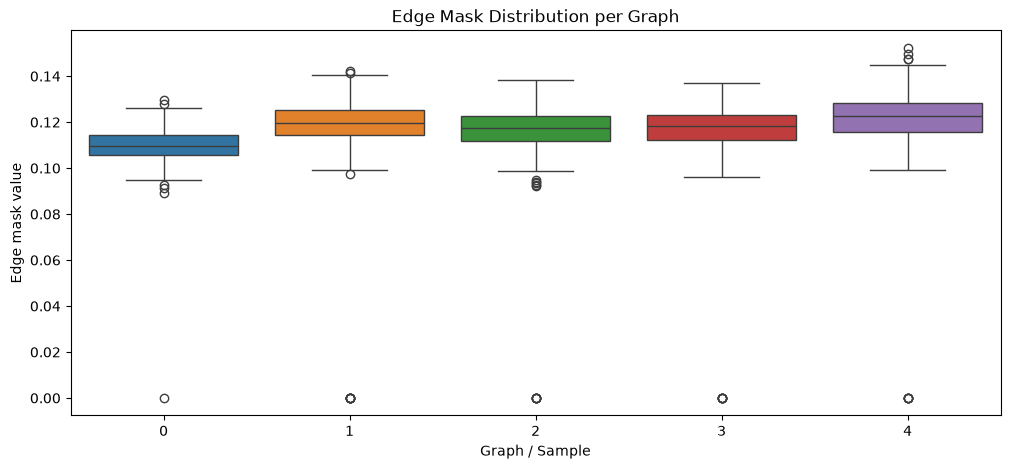

In [16]:
mask_values = [
    t.detach().cpu().numpy().flatten()
    for t in edge_masks
]

plt.figure(figsize=(12, 5))

sns.boxplot(data=mask_values[:5])

plt.xlabel("Graph / Sample")
plt.ylabel("Edge mask value")
plt.title("Edge Mask Distribution per Graph")

plt.show()

In [17]:
rows = []

for result in results:

    if result["label"] != result["pred"]:
        continue

    edge_index = result["edge_index"]

    num_edges = (edge_index[0] != edge_index[1]).sum().item()

    rows.append({
        "class": "Human" if result["label"] == 0 else "Machine",
        "num_edges": num_edges
    })

df_edges = pd.DataFrame(rows)

display(
    df_edges.groupby("class")["num_edges"].agg(
        ["count", "mean", "median", "min", "max"]
    )
)

,count,mean,median,min,max
class,,,,,
Human,180,364.477778,331.0,122,895
Machine,178,160.410112,160.5,40,325


In [18]:
selected_results = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\expl_none_object_motif_edges_top_0p050.pth",
    map_location="cpu",
        weights_only=False
)

In [19]:
rows = []

for selected, motif_result in zip(selected_results, motif_results):

    if selected["row"] != motif_result["row"]:
        raise ValueError("Graph order does not match")

    if selected["label"] != selected["pred"]:
        continue

    edges = {
        (int(u), int(v))
        for u, v in selected["edge_index"].T.tolist()
        if u != v
    }

    k = len(edges)

    M = motif_result["num_motifs"]

    possible_pairs = math.comb(k, 2)

    interconnectedness = (
        M / possible_pairs
        if possible_pairs > 0 else float("nan")
    )

    rows.append({
        "class": "Human" if selected["label"] == 0 else "Machine",
        "selected_edges": k,
        "num_motifs": M,
        "possible_pairs": possible_pairs,
        "interconnectedness": interconnectedness
    })

df_connectivity = pd.DataFrame(rows)

In [20]:
display(
    df_connectivity.groupby("class")[
        ["selected_edges", "num_motifs", "interconnectedness"]
    ].agg(["mean", "median"])
)

selected_edges        num_motifs        interconnectedness          
                  mean median       mean median               mean    median
class                                                                       
Human        18.677778   17.0  21.127778   17.0           0.126337  0.110294
Machine       8.516854    8.5   3.050562    2.0           0.086266  0.066667

### 2. Analyze words in the motifs per class

In [21]:
def count_function_words(df, column, fwords):
    counts = Counter()

    for _, row in df[df[column] > 0].iterrows():
        motif = row["motif"]

        if isinstance(motif, str):
            motif = ast.literal_eval(motif)

        nodes = {
            node 
            for edge in motif
            for node in edge
        }

        for node in nodes:
            counts[fwords[node]] += 1
            
    return pd.DataFrame(
        counts.most_common(),
        columns=["word", "count"]
    )
    

In [22]:
human_words = count_function_words(df, "human_selected", fwords)
human_words

,word,count
0,further,793
1,herein,738
2,a,502
3,afterwards,469
4,from,421
...,...,...
99,do,2
100,be,2
101,another,1
102,hereafter,1


In [23]:
machine_words = count_function_words(df, "machine_selected", fwords)
machine_words

,word,count
0,herein,123
1,eg,79
2,against,68
3,afterwards,67
4,behind,58
...,...,...
83,elsewhere,1
84,an,1
85,between,1
86,have,1


In [24]:
word_comparison = human_words.rename(
    columns={"count": "human_count"}
    ).merge(
        machine_words.rename(
            columns={"count": "machine_count"}
        ),
        on="word",
        how="outer"
    ).fillna(0)

word_comparison["difference"] = (
    word_comparison["human_count"] - word_comparison["machine_count"]
)

word_comparison


,word,human_count,machine_count,difference
0,a,502.0,25.0,477.0
1,about,77.0,19.0,58.0
2,above,111.0,8.0,103.0
3,across,10.0,13.0,-3.0
4,after,56.0,26.0,30.0
...,...,...,...,...
101,inside,23.0,10.0,13.0
102,instead,125.0,12.0,113.0
103,into,277.0,2.0,275.0
104,is,78.0,0.0,78.0


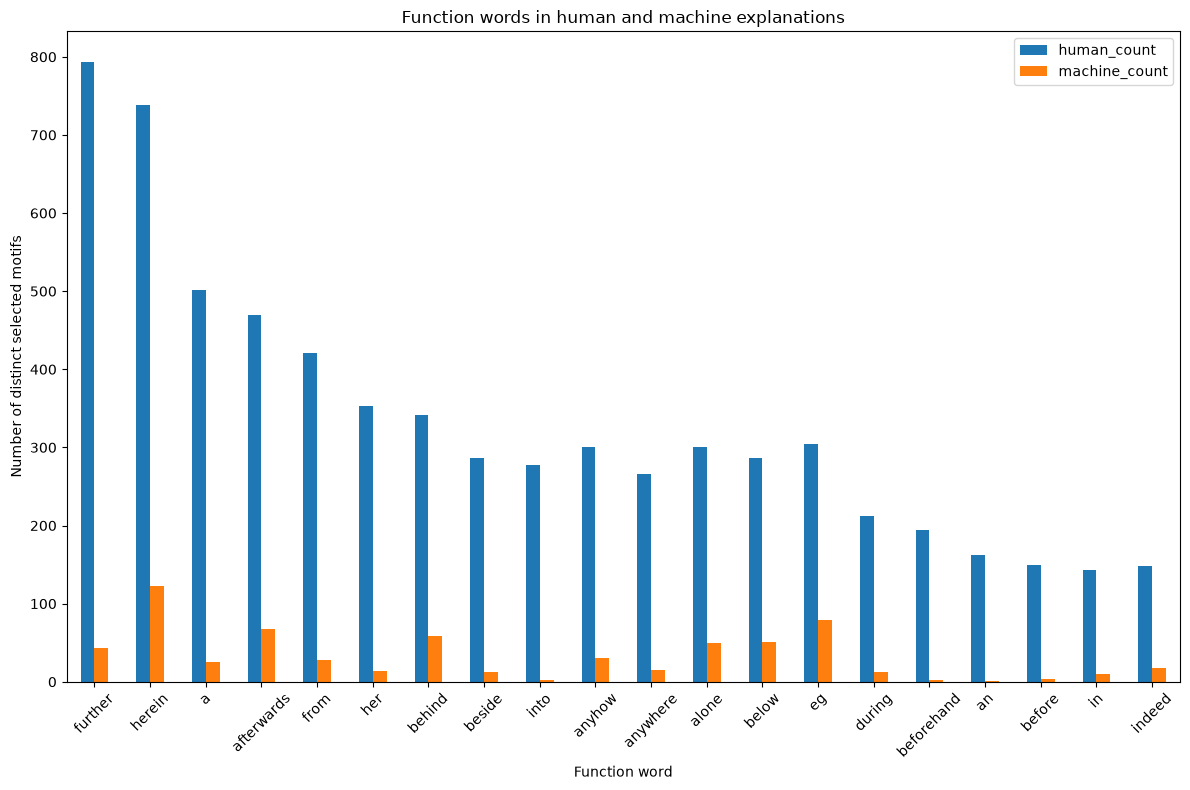

In [25]:
top_words = word_comparison.sort_values(
    "difference",
    key=abs,
    ascending=False
).head(20)

top_words = top_words.set_index("word")

top_words[["human_count", "machine_count"]].plot(
    kind="bar",
    figsize=(12,8)
)

plt.xlabel("Function word")
plt.ylabel("Number of distinct selected motifs")
plt.title("Function words in human and machine explanations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()